In [1]:
import pandas as pd
import seaborn as sns
import statistics as sts

In [2]:
df = pd.read_csv(r'C:/Users/guilherme_doge1/Desktop/Ciência de Dados/Aula 15 - 23-11-2026/telemetria_parque_fabril_5000.csv', sep=',')

In [3]:
df.head()

,id_registro,timestamp,id_maquina,turno,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha
0,1,2026-10-01 06:00:00,Prensa_Hidraulica_02,Manhã,75.47,4.30,31.09,1188.6,153.86,25.16,29.1,0
1,2,2026-10-01 06:01:00,Robo_Solda_05,Manhã,86.23,3.23,41.31,1561.2,83.41,26.27,41.1,0
2,3,2026-10-01 06:02:00,Injetora_Plastico_04,Manhã,71.84,1.14,40.23,1608.2,159.75,31.20,14.4,0
3,4,2026-10-01 06:03:00,Fresadora_CNC_03,Manhã,64.37,6.10,48.78,2378.7,149.04,38.09,33.6,0
4,5,2026-10-01 06:04:00,Torno_CNC_01,Manhã,71.06,4.51,39.31,2035.0,110.90,28.05,28.9,0


In [4]:
df.tail()

,id_registro,timestamp,id_maquina,turno,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha
4995,4996,2026-10-04 16:31:00,Torno_CNC_01,Tarde,74.06,2.24,25.27,2065.2,98.29,23.18,25.6,0
4996,4997,2026-10-04 16:31:00,Torno_CNC_01,Tarde,74.06,2.24,25.27,2065.2,98.29,23.18,25.6,0
4997,4998,2026-10-04 16:32:00,Prensa_Hidraulica_02,Tarde,78.11,7.26,46.70,997.8,198.81,35.23,53.9,0
4998,4999,2026-10-04 16:33:00,Injetora_Plastico_04,Tarde,64.39,1.86,28.27,1062.8,171.20,24.49,12.6,0
4999,5000,2026-10-04 16:34:00,Fresadora_CNC_03,Tarde,44.42,1.11,26.53,1962.9,136.01,23.56,5.8,0


In [5]:
df.describe()

,id_registro,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha
count,5000.000000,4945.000000,4950.000000,4960.000000,5000.000000,4965.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,69.163589,4.373616,38.409641,1609.679460,142.791253,29.634680,32.914160,0.111800
std,1443.520003,39.564071,2.694934,9.854764,1514.052799,34.517372,5.520381,15.888024,0.315152
min,1.000000,-999.000000,-3.500000,8.000000,0.000000,63.260000,8.950000,2.500000,0.000000
25%,1250.750000,60.870000,2.822500,31.407500,1114.800000,115.990000,25.847500,21.900000,0.000000
50%,2500.500000,69.350000,4.120000,37.955000,1495.850000,136.140000,29.470000,28.600000,0.000000
75%,3750.250000,77.860000,5.590000,44.972500,1988.725000,168.510000,33.340000,41.825000,0.000000
max,5000.000000,512.000000,85.000000,75.000000,99999.000000,240.000000,50.930000,89.300000,1.000000


In [6]:
df.shape

(5000, 12)

In [7]:
df.drop_duplicates(subset="id_registro", keep="first", inplace=True)

In [8]:
print(df.groupby(['temperatura_operacao_c']).size())
print("======================================================")
print(df['temperatura_operacao_c'].describe())
print("======================================================")
print(df["temperatura_operacao_c"].isnull().sum())
print(df["temperatura_operacao_c"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.loc[(df["temperatura_operacao_c"] > 200) | (df["temperatura_operacao_c"] < -273), "temperatura_operacao_c"] = df["temperatura_operacao_c"].median()
df.loc[df["temperatura_operacao_c"].isnull(), "temperatura_operacao_c"] = df["temperatura_operacao_c"].median()
print(df["temperatura_operacao_c"].isnull().sum())
print(df["temperatura_operacao_c"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
print(df['temperatura_operacao_c'].describe())

temperatura_operacao_c
-999.00     5
 35.00      6
 35.62      1
 36.03      1
 36.19      1
           ..
 104.24     1
 104.46     1
 105.00    17
 480.50     3
 512.00     4
Length: 2968, dtype: int64
count    4945.000000
mean       69.163589
std        39.564071
min      -999.000000
25%        60.870000
50%        69.350000
75%        77.860000
max       512.000000
Name: temperatura_operacao_c, dtype: float64
55
1.0999999999999999
0
0.0
count    5000.00000
mean       69.63318
std        12.17450
min        35.00000
25%        60.97750
50%        69.35000
75%        77.68250
max       105.00000
Name: temperatura_operacao_c, dtype: float64


In [9]:
print(df.groupby(['vibracao_mms']).size())
print("======================================================")
print(df['vibracao_mms'].describe())
print("======================================================")
print(df["vibracao_mms"].isnull().sum())
print(df["vibracao_mms"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.loc[(df["vibracao_mms"] > 10) | (df["vibracao_mms"] < 0), "vibracao_mms"] = df["vibracao_mms"].median()
df.loc[df["vibracao_mms"].isnull(), "vibracao_mms"] = df["vibracao_mms"].median()
print(df["vibracao_mms"].isnull().sum())
print(df["vibracao_mms"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
print(df['vibracao_mms'].describe())

vibracao_mms
-3.50      4
-1.20      6
 0.40     76
 0.41      1
 0.42      1
          ..
 13.36     1
 13.72     1
 13.77     1
 14.50     1
 85.00     2
Length: 922, dtype: int64
count    4950.000000
mean        4.373616
std         2.694934
min        -3.500000
25%         2.822500
50%         4.120000
75%         5.590000
max        85.000000
Name: vibracao_mms, dtype: float64
50
1.0
0
0.0
count    5000.000000
mean        4.251098
std         1.953989
min         0.400000
25%         2.850000
50%         4.120000
75%         5.440000
max        10.000000
Name: vibracao_mms, dtype: float64


In [10]:
print(df.groupby(['corrente_eletrica_a']).size())
print("======================================================")
print(df['corrente_eletrica_a'].describe())
print("======================================================")
print(df["corrente_eletrica_a"].isnull().sum())
print(df["corrente_eletrica_a"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.loc[(df["corrente_eletrica_a"] > 100) | (df["corrente_eletrica_a"] < 0), "corrente_eletrica_a"] = df["corrente_eletrica_a"].median()
df.loc[df["corrente_eletrica_a"].isnull(), "corrente_eletrica_a"] = df["corrente_eletrica_a"].median()
print(df["corrente_eletrica_a"].isnull().sum())
print(df["corrente_eletrica_a"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
print(df['corrente_eletrica_a'].describe())

corrente_eletrica_a
8.00     1
8.99     2
9.43     1
12.61    1
13.57    1
        ..
72.92    1
73.02    1
73.95    1
74.28    1
75.00    1
Length: 2718, dtype: int64
count    4960.000000
mean       38.409641
std         9.854764
min         8.000000
25%        31.407500
50%        37.955000
75%        44.972500
max        75.000000
Name: corrente_eletrica_a, dtype: float64
40
0.8
0
0.0
count    5000.000000
mean       38.406004
std         9.815342
min         8.000000
25%        31.450000
50%        37.955000
75%        44.930000
max        75.000000
Name: corrente_eletrica_a, dtype: float64


In [11]:
print(df.groupby(['rotacao_rpm']).size())
print("======================================================")
print(df['rotacao_rpm'].describe())
print("======================================================")
print(df["rotacao_rpm"].isnull().sum())
print(df["rotacao_rpm"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.loc[(df["rotacao_rpm"] > 1000) | (df["rotacao_rpm"] < 0), "rotacao_rpm"] = df["rotacao_rpm"].median()
df.loc[df["rotacao_rpm"].isnull(), "rotacao_rpm"] = df["rotacao_rpm"].median()
print(df["rotacao_rpm"].isnull().sum())
print(df["rotacao_rpm"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
print(df["rotacao_rpm"].describe())

rotacao_rpm
0.0        10
600.0      32
603.5       1
604.2       1
605.3       1
           ..
3431.4      1
3452.3      1
3506.0      1
3518.4      1
99999.0     1
Length: 4348, dtype: int64
count     5000.000000
mean      1609.679460
std       1514.052799
min          0.000000
25%       1114.800000
50%       1495.850000
75%       1988.725000
max      99999.000000
Name: rotacao_rpm, dtype: float64
0
0.0
0
0.0
count    5000.000000
mean     1385.328640
std       252.366896
min         0.000000
25%      1495.850000
50%      1495.850000
75%      1495.850000
max      1495.850000
Name: rotacao_rpm, dtype: float64


In [12]:
print(df.groupby(['pressao_hidraulica_bar']).size())
print("======================================================")
print(df['pressao_hidraulica_bar'].describe())
print("======================================================")
print(df["pressao_hidraulica_bar"].isnull().sum())
print(df["pressao_hidraulica_bar"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.loc[(df["pressao_hidraulica_bar"] > 500) | (df["pressao_hidraulica_bar"] < 0), "pressao_hidraulica_bar"] = df["pressao_hidraulica_bar"].median()
df.loc[df["pressao_hidraulica_bar"].isnull(), "pressao_hidraulica_bar"] = df["pressao_hidraulica_bar"].median()
print(df["pressao_hidraulica_bar"].isnull().sum())
print(df["pressao_hidraulica_bar"].isnull().sum() / df.shape[0] * 100)

pressao_hidraulica_bar
63.26     1
65.52     1
66.46     1
68.75     1
70.13     1
         ..
237.51    1
237.70    1
238.37    1
239.01    1
240.00    5
Length: 4030, dtype: int64
count    4965.000000
mean      142.791253
std        34.517372
min        63.260000
25%       115.990000
50%       136.140000
75%       168.510000
max       240.000000
Name: pressao_hidraulica_bar, dtype: float64
35
0.7000000000000001
0
0.0


In [13]:
print(df.groupby(['consumo_energia_kwh']).size())
print("======================================================")
print(df['consumo_energia_kwh'].describe())
print("======================================================")
print(df["consumo_energia_kwh"].isnull().sum())
print(df["consumo_energia_kwh"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.loc[df["consumo_energia_kwh"].isnull(), "consumo_energia_kwh"] = df["consumo_energia_kwh"].median()
df.loc[(df["consumo_energia_kwh"] > 1000) | (df["consumo_energia_kwh"] < 0), "consumo_energia_kwh"] = df["consumo_energia_kwh"].median()
print(df["consumo_energia_kwh"].isnull().sum())
print(df["consumo_energia_kwh"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
print(df['vibracao_mms'].describe())

consumo_energia_kwh
8.95     1
12.08    1
13.96    1
14.23    1
14.88    1
        ..
48.90    1
49.13    1
49.23    1
50.08    1
50.93    1
Length: 1979, dtype: int64
count    5000.000000
mean       29.634680
std         5.520381
min         8.950000
25%        25.847500
50%        29.470000
75%        33.340000
max        50.930000
Name: consumo_energia_kwh, dtype: float64
0
0.0
0
0.0
count    5000.000000
mean        4.251098
std         1.953989
min         0.400000
25%         2.850000
50%         4.120000
75%         5.440000
max        10.000000
Name: vibracao_mms, dtype: float64


In [14]:
print(df.groupby(['desgaste_ferramenta_pct']).size())
print("======================================================")
print(df['desgaste_ferramenta_pct'].describe())
print("======================================================")
print(df["desgaste_ferramenta_pct"].isnull().sum())
print(df["desgaste_ferramenta_pct"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.loc[(df["desgaste_ferramenta_pct"] > 1) | (df["desgaste_ferramenta_pct"] < 0), "desgaste_ferramenta_pct"] = df["desgaste_ferramenta_pct"].median()
df.loc[df["desgaste_ferramenta_pct"].isnull(), "desgaste_ferramenta_pct"] = df["desgaste_ferramenta_pct"].median()
print(df["desgaste_ferramenta_pct"].isnull().sum())
print(df["desgaste_ferramenta_pct"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
print(df['vibracao_mms'].describe())

desgaste_ferramenta_pct
2.5     1
2.8     1
3.1     2
5.1     1
5.2     1
       ..
86.4    1
87.0    2
87.8    1
88.2    1
89.3    1
Length: 717, dtype: int64
count    5000.000000
mean       32.914160
std        15.888024
min         2.500000
25%        21.900000
50%        28.600000
75%        41.825000
max        89.300000
Name: desgaste_ferramenta_pct, dtype: float64
0
0.0
0
0.0
count    5000.000000
mean        4.251098
std         1.953989
min         0.400000
25%         2.850000
50%         4.120000
75%         5.440000
max        10.000000
Name: vibracao_mms, dtype: float64


In [15]:
print(df.groupby(['status_falha']).size())
print("======================================================")
print(df['status_falha'].describe())
print("======================================================")
print(df["status_falha"].isnull().sum())
print(df["status_falha"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.loc[(df["status_falha"] != 1) & (df["status_falha"] != 0), "status_falha"] = df["status_falha"].mode()
df.loc[df["status_falha"].isnull(), "status_falha"] = df["status_falha"].mode()
print(df["status_falha"].isnull().sum())
print(df["status_falha"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
print(df['status_falha'].describe())

status_falha
0    4441
1     559
dtype: int64
count    5000.000000
mean        0.111800
std         0.315152
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: status_falha, dtype: float64
0
0.0
0
0.0
count    5000.000000
mean        0.111800
std         0.315152
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: status_falha, dtype: float64


id_maquina
Fresadora_CNC_03        1063
Injetora_Plastico_04     908
Prensa_Hidraulica_02    1022
Robo_Solda_05            884
Torno_CNC_01            1123
dtype: int64
count             5000
unique               5
top       Torno_CNC_01
freq              1123
Name: id_maquina, dtype: object
0
0.0


<Axes: xlabel='id_maquina'>

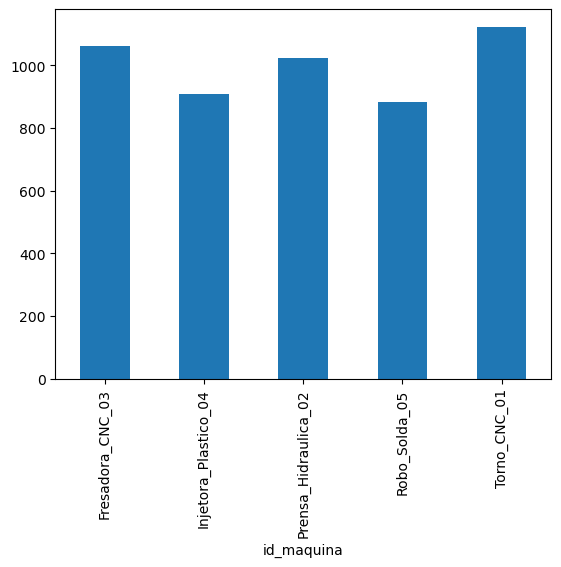

In [16]:
print(df.groupby(['id_maquina']).size())
print("======================================================")
print(df['id_maquina'].describe())
print("======================================================")
print(df["id_maquina"].isnull().sum())
print(df["id_maquina"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.groupby(["id_maquina"]).size().plot.bar()

turno
 Tarde       2
MANHA       11
Manhã     1911
Manhã        9
NOITE        4
Noite     1434
Noite       11
TARDE        4
Tarde     1595
manha        8
noite        4
tarde        7
dtype: int64
count      5000
unique       12
top       Manhã
freq       1911
Name: turno, dtype: object
0
0.0


<Axes: xlabel='turno'>

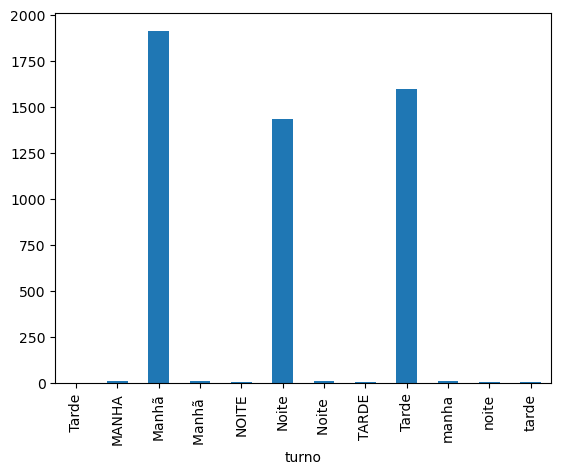

In [17]:
print(df.groupby(['turno']).size())
print("======================================================")
print(df['turno'].describe())
print("======================================================")
print(df["turno"].isnull().sum())
print(df["turno"].isnull().sum() / df.shape[0] * 100)
print("======================================================")
df.groupby(["turno"]).size().plot.bar()

<Axes: xlabel='turno'>

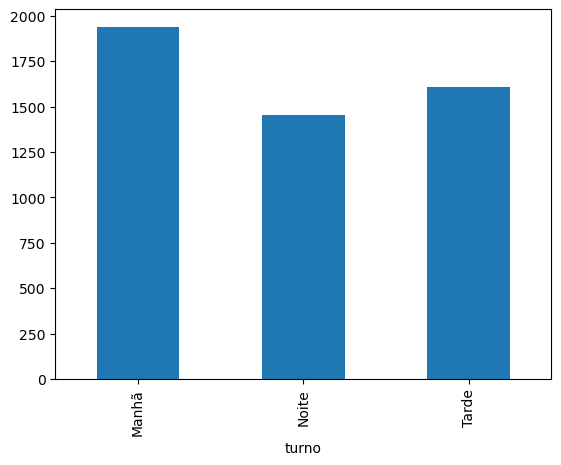

In [18]:
df["turno"] = df["turno"].str.strip()
df.loc[df["turno"].isin(["Tarde", "TARDE", "Tarde", "tarde"]), "turno"] = "Tarde"
df.loc[df["turno"].isin(["MANHA", "Manhã", "Manhã", "manha"]), "turno"] = "Manhã"
df.loc[df["turno"].isin(["NOITE", "Noite", "Noite", "noite"]), "turno"] = "Noite"
df.groupby(["turno"]).size().plot.bar()

In [19]:
df.isnull().sum()

id_registro                0
timestamp                  0
id_maquina                 0
turno                      0
temperatura_operacao_c     0
vibracao_mms               0
corrente_eletrica_a        0
rotacao_rpm                0
pressao_hidraulica_bar     0
consumo_energia_kwh        0
desgaste_ferramenta_pct    0
status_falha               0
dtype: int64

In [21]:
df[df.duplicated(["id_registro"], keep=False)]

,id_registro,timestamp,id_maquina,turno,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha


In [22]:
df.head()

,id_registro,timestamp,id_maquina,turno,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha
0,1,2026-10-01 06:00:00,Prensa_Hidraulica_02,Manhã,75.47,4.30,31.09,1495.85,153.86,25.16,28.6,0
1,2,2026-10-01 06:01:00,Robo_Solda_05,Manhã,86.23,3.23,41.31,1495.85,83.41,26.27,28.6,0
2,3,2026-10-01 06:02:00,Injetora_Plastico_04,Manhã,71.84,1.14,40.23,1495.85,159.75,31.20,28.6,0
3,4,2026-10-01 06:03:00,Fresadora_CNC_03,Manhã,64.37,6.10,48.78,1495.85,149.04,38.09,28.6,0
4,5,2026-10-01 06:04:00,Torno_CNC_01,Manhã,71.06,4.51,39.31,1495.85,110.90,28.05,28.6,0


In [23]:
df.tail()

,id_registro,timestamp,id_maquina,turno,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha
4995,4996,2026-10-04 16:31:00,Torno_CNC_01,Tarde,74.06,2.24,25.27,1495.85,98.29,23.18,28.6,0
4996,4997,2026-10-04 16:31:00,Torno_CNC_01,Tarde,74.06,2.24,25.27,1495.85,98.29,23.18,28.6,0
4997,4998,2026-10-04 16:32:00,Prensa_Hidraulica_02,Tarde,78.11,7.26,46.70,997.80,198.81,35.23,28.6,0
4998,4999,2026-10-04 16:33:00,Injetora_Plastico_04,Tarde,64.39,1.86,28.27,1495.85,171.20,24.49,28.6,0
4999,5000,2026-10-04 16:34:00,Fresadora_CNC_03,Tarde,44.42,1.11,26.53,1495.85,136.01,23.56,28.6,0


In [24]:
df.describe()

,id_registro,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03,5000.000000
mean,2500.500000,69.63318,4.251098,38.406004,1385.328640,142.744694,29.634680,2.860000e+01,0.111800
std,1443.520003,12.17450,1.953989,9.815342,252.366896,34.400795,5.520381,2.682567e-12,0.315152
min,1.000000,35.00000,0.400000,8.000000,0.000000,63.260000,8.950000,2.860000e+01,0.000000
25%,1250.750000,60.97750,2.850000,31.450000,1495.850000,116.105000,25.847500,2.860000e+01,0.000000
50%,2500.500000,69.35000,4.120000,37.955000,1495.850000,136.140000,29.470000,2.860000e+01,0.000000
75%,3750.250000,77.68250,5.440000,44.930000,1495.850000,168.360000,33.340000,2.860000e+01,0.000000
max,5000.000000,105.00000,10.000000,75.000000,1495.850000,240.000000,50.930000,2.860000e+01,1.000000


In [27]:
df.to_csv("./dados_fabrica_limpos.csv", index=False)